<a href="https://colab.research.google.com/github/Ariqq16/ML_2026/blob/main/JS08/Tugas_Lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Langkah 1 - Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

from google.colab import files

uploaded = files.upload()

nama_file = next(iter(uploaded))
df = pd.read_csv('/content/sample_data/CC_Customer_Dataset.csv')

print("Lima data pertama:")
display(df.head())

print("Ukuran dataset:", df.shape)
print("\nInformasi dataset:")
df.info()

print("\nJumlah missing value:")
print(df.isnull().sum())

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv
Lima data pertama:


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


Ukuran dataset: (660, 7)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Jumlah missing value:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64


In [4]:
# Langkah 2 - Memilih fitur yang digunakan
fitur = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]

X = df[fitur].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Jumlah data:", X_scaled.shape[0])
print("Jumlah fitur:", X_scaled.shape[1])
print("\nContoh hasil standardisasi:")
print(X_scaled[:5])

Jumlah data: 660
Jumlah fitur: 5

Contoh hasil standardisasi:
[[ 1.74018685 -1.24922476 -0.86045063 -0.54748969 -1.25153737]
 [ 0.41029254 -0.78758515 -1.47373077  2.5205186   1.89185881]
 [ 0.41029254  1.05897329 -0.86045063  0.13428993  0.1455276 ]
 [-0.12166518  0.13569407 -0.86045063 -0.54748969  0.1455276 ]
 [ 1.74018685  0.59733368 -1.47373077  3.20229822 -0.20373864]]


In [5]:
# Langkah 3 - Evaluasi beberapa jumlah cluster
hasil_evaluasi = []

for k in range(2, 9):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(X_scaled)

    silhouette = silhouette_score(X_scaled, labels)
    dbi = davies_bouldin_score(X_scaled, labels)

    hasil_evaluasi.append({
        'Jumlah Cluster': k,
        'Silhouette Score': silhouette,
        'DBI': dbi
    })

hasil_df = pd.DataFrame(hasil_evaluasi)

print("Hasil evaluasi jumlah cluster:")
display(hasil_df.round(4))

Hasil evaluasi jumlah cluster:


,Jumlah Cluster,Silhouette Score,DBI
0,2,0.4177,0.9326
1,3,0.5148,0.6810
2,4,0.3481,1.1493
3,5,0.2569,1.3851
4,6,0.2268,1.4109
5,7,0.2163,1.4394
6,8,0.2187,1.4489


In [6]:
# Langkah 4 - Membuat model final
model = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

labels = model.fit_predict(X_scaled)

df['Cluster'] = labels

print("Jumlah data pada setiap cluster:")
print(df['Cluster'].value_counts().sort_index())

print("\nContoh hasil klasterisasi:")
display(df.head(10))

Jumlah data pada setiap cluster:
Cluster
0    385
1    225
2     50
Name: count, dtype: int64

Contoh hasil klasterisasi:


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Cluster
0,1,87073,100000,2,1,1,0,0
1,2,38414,50000,3,0,10,9,1
2,3,17341,50000,7,1,3,4,0
3,4,40496,30000,5,1,1,4,0
4,5,47437,100000,6,0,12,3,2
5,6,58634,20000,3,0,1,8,1
6,7,48370,100000,5,0,11,2,2
7,8,37376,15000,3,0,1,1,1
8,9,82490,5000,2,0,2,2,1
9,10,44770,3000,4,0,1,7,1


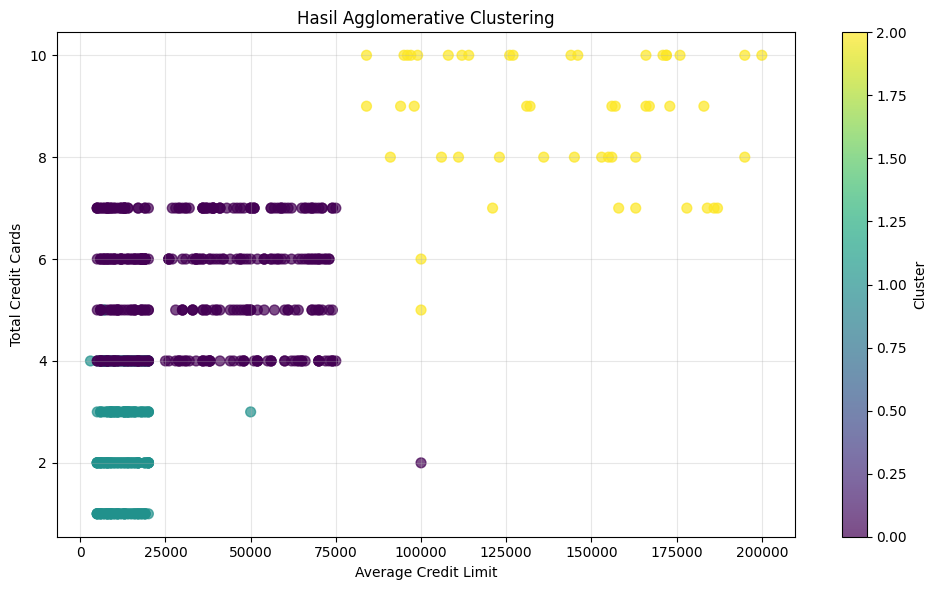

In [7]:
# Langkah 5 - Scatterplot hasil klasterisasi
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    df['Avg_Credit_Limit'],
    df['Total_Credit_Cards'],
    c=df['Cluster'],
    cmap='viridis',
    s=50,
    alpha=0.7
)

plt.title('Hasil Agglomerative Clustering')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')

plt.colorbar(scatter, label='Cluster')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Langkah 6 - Evaluasi model final
silhouette = silhouette_score(X_scaled, labels)
dbi = davies_bouldin_score(X_scaled, labels)

print("Evaluasi Agglomerative Clustering")
print("---------------------------------")
print("Jumlah cluster :", len(np.unique(labels)))
print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Index (DBI):", round(dbi, 4))

Evaluasi Agglomerative Clustering
---------------------------------
Jumlah cluster : 3
Silhouette Score: 0.5148
Davies-Bouldin Index (DBI): 0.681


In [9]:
# Langkah 7 - Analisis karakteristik cluster
profil_cluster = df.groupby('Cluster')[fitur].mean().round(2)

print("Rata-rata fitur setiap cluster:")
display(profil_cluster)

Rata-rata fitur setiap cluster:


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster,,,,,
0,33851.95,5.52,3.49,0.98,1.99
1,12151.11,2.42,0.94,3.55,6.86
2,141040.00,8.74,0.60,10.90,1.08
